# Capitolo 6 — Geometria multivista e ricostruzione
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo06` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo06')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


## N6.A1 — Disparità, profondità e sensibilità

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

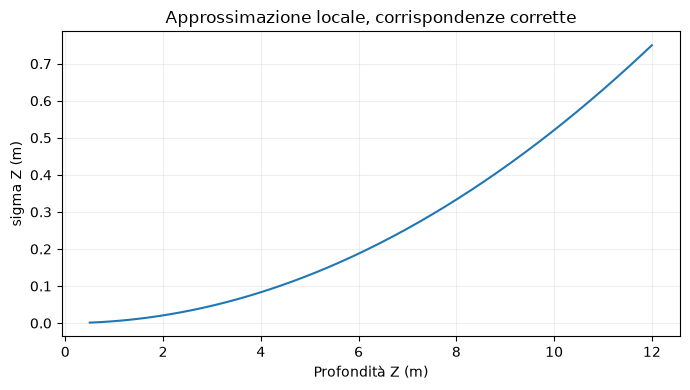

Disparità: [48. 24. 12.  0. -2.] profondità con maschera: [ 2.  4.  8. nan nan]


In [2]:
f, B, sigma_d = 800., 0.12, 0.5
disparita = np.array([48., 24., 12., 0., -2.])
valida = disparita > 0
profondita = np.full(disparita.shape, np.nan)
profondita[valida] = f*B/disparita[valida]
z = np.linspace(0.5,12,300)
sigma_z = z*z*sigma_d/(f*B)
metriche['profondita_disparita_24_m'] = float(f*B/24)
metriche['sigmaZ_a_4m_m'] = float(4**2*sigma_d/(f*B))
plt.plot(z, sigma_z)
plt.xlabel('Profondità Z (m)'); plt.ylabel('sigma Z (m)')
plt.title('Approssimazione locale, corrispondenze corrette')
plt.grid(alpha=0.2); salva_figura('A1_incertezza')
print('Disparità:', disparita, 'profondità con maschera:', profondita)


**Domande**

1. Interpretare la crescita quadratica e confrontare 4 e 8 metri.
2. Spiegare il trattamento di disparità nulle e negative e i limiti della propagazione locale.

## N6.A2 — Triangolazione di osservazioni virtuali

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

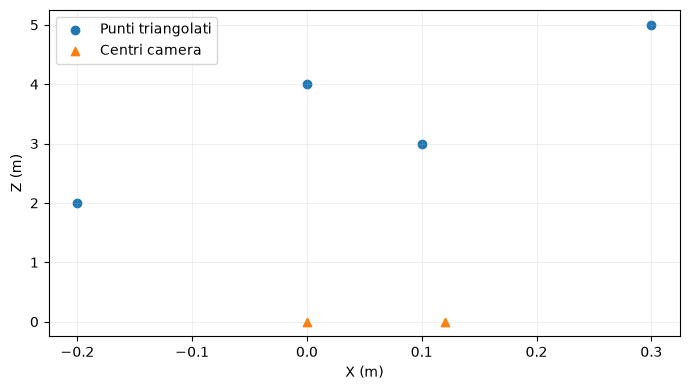

In [3]:
K = np.array([[800.,0,320], [0,800.,240], [0,0,1.]])
P1 = K @ np.c_[np.eye(3), np.zeros(3)]
P2 = K @ np.c_[np.eye(3), np.array([-B,0,0])]
X_veri = np.array([[-0.2,-0.1,2.], [0.1,0.2,3.], [0.3,-0.2,5.], [0.,0.,4.]])
uv1, uv2 = proietta(P1,X_veri), proietta(P2,X_veri)
def triangola(P1, P2, u, v):
    A = np.array([u[0]*P1[2]-P1[0], u[1]*P1[2]-P1[1],
                  v[0]*P2[2]-P2[0], v[1]*P2[2]-P2[1]])
    _, _, Vt = np.linalg.svd(A)
    q = Vt[-1]
    return q[:3]/q[3]
X_stimati = np.array([triangola(P1,P2,u,v) for u,v in zip(uv1,uv2)])
metriche['errore_massimo_triangolazione_m'] = float(np.max(np.linalg.norm(X_stimati-X_veri,axis=1)))
metriche['errore_massimo_riproiezione_pixel'] = float(np.max(np.linalg.norm(proietta(P2,X_stimati)-uv2,axis=1)))
np.savetxt(OUTPUT/'A2_punti_3D.csv', X_stimati, delimiter=',', header='X_m,Y_m,Z_m', comments='')
plt.scatter(X_stimati[:,0],X_stimati[:,2],label='Punti triangolati')
plt.scatter([0,B],[0,0],marker='^',label='Centri camera')
plt.xlabel('X (m)'); plt.ylabel('Z (m)'); plt.legend(); plt.grid(alpha=0.2)
salva_figura('A2_triangolazione')


**Domande**

1. Controllare errore 3D, riproiezione e profondità nelle due camere.
2. Spiegare perché piccoli residui non garantiscono accuratezza 3D con raggi quasi paralleli.

## N6.A3 — Gauge di scala

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

In [4]:
fattore = 3.
P2_scalata = K @ np.c_[np.eye(3), np.array([-fattore*B,0,0])]
uv1_scalati = proietta(P1, fattore*X_veri)
uv2_scalati = proietta(P2_scalata, fattore*X_veri)
metriche['errore_scala_vista1_pixel'] = float(np.max(np.abs(uv1_scalati-uv1)))
metriche['errore_scala_vista2_pixel'] = float(np.max(np.abs(uv2_scalati-uv2)))
print('Differenza pixel dopo scala globale:', metriche['errore_scala_vista1_pixel'], metriche['errore_scala_vista2_pixel'])
print('Distanze dal primo centro:', np.linalg.norm(X_veri,axis=1))
print('Distanze dopo scala:', np.linalg.norm(fattore*X_veri,axis=1))


Differenza pixel dopo scala globale: 0.0 0.0
Distanze dal primo centro: [2.01246118 3.00832179 5.01298314 4.        ]
Distanze dopo scala: [ 6.03738354  9.02496537 15.03894943 12.        ]


**Domande**

1. Derivare l’invarianza dei pixel e distinguere questa libertà dalla scala omogenea di un singolo punto.
2. Proporre un dato metrico indipendente che permetta di fissare la scala.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [5]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo06
